In [2]:
# import library 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score
from sklearn.utils import shuffle
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [3]:
# import data
import pandas as pd
file_path = "C:/Users/Keysha Jauzi/Documents/Magang/Data Magang.xlsx"
df = pd.read_excel(file_path, sheet_name='Sheet1')
df = df.set_index('Kabupaten/Kota')
df

,UHH,RLS,Presentase Miskin
Kabupaten/Kota,,,
Kabupaten Bogor,74.90,8.39,7.05
Kabupaten Sukabumi,74.85,7.34,6.87
Kabupaten Cianjur,75.80,7.33,10.14
Kabupaten Bandung,75.23,9.15,6.19
Kabupaten Garut,74.87,7.85,9.68
Kabupaten Tasikmalaya,74.06,7.97,10.23
Kabupaten Ciamis,75.26,8.10,7.39
Kabupaten Kuningan,75.22,7.90,11.88
Kabupaten Cirebon,74.98,7.65,11.00


In [4]:
# Preproccessing Data
# Cek Missing Values
print(df.isnull().sum())

UHH                  0
RLS                  0
Presentase Miskin    0
dtype: int64


In [5]:
# Cek Duplikat
print(df.duplicated().sum())

0


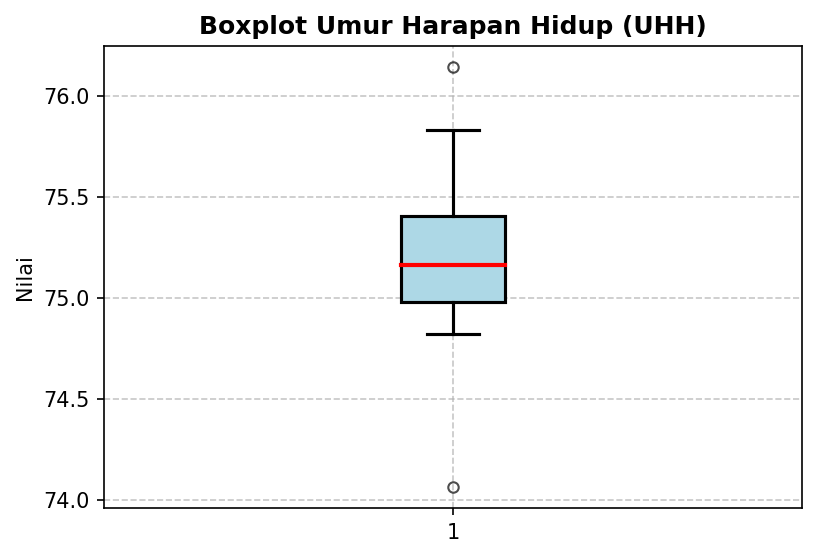

In [6]:
# Cek Outlier
import matplotlib.pyplot as plt

# Boxplot UHH
plt.figure(figsize=(6, 4), dpi=150)
plt.boxplot(df['UHH'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='black', linewidth=1.5),
            medianprops=dict(color='red', linewidth=2),
            whiskerprops=dict(color='black', linewidth=1.5),
            capprops=dict(color='black', linewidth=1.5),
            flierprops=dict(marker='o', color='black', markersize=5, alpha=0.7))
plt.title('Boxplot Umur Harapan Hidup (UHH)', fontsize=12, fontweight='bold')
plt.ylabel('Nilai', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


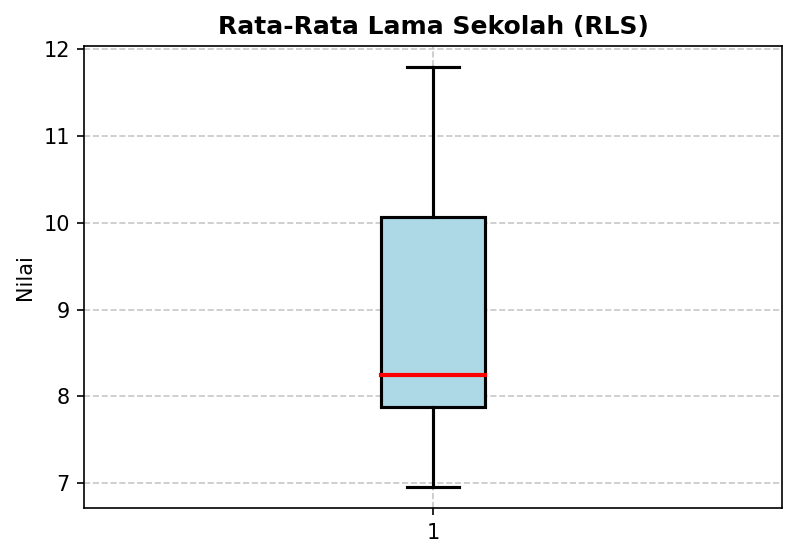

In [7]:
import matplotlib.pyplot as plt

# Boxplot UHH
plt.figure(figsize=(6, 4), dpi=150)
plt.boxplot(df['RLS'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='black', linewidth=1.5),
            medianprops=dict(color='red', linewidth=2),
            whiskerprops=dict(color='black', linewidth=1.5),
            capprops=dict(color='black', linewidth=1.5),
            flierprops=dict(marker='o', color='black', markersize=5, alpha=0.7))
plt.title('Rata-Rata Lama Sekolah (RLS)', fontsize=12, fontweight='bold')
plt.ylabel('Nilai', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


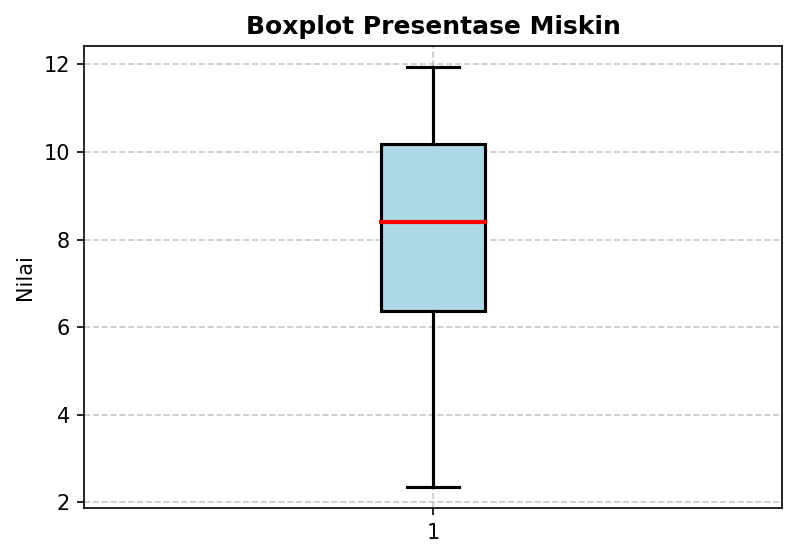

In [8]:
import matplotlib.pyplot as plt

# Boxplot UHH
plt.figure(figsize=(6, 4), dpi=150)
plt.boxplot(df['Presentase Miskin'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='black', linewidth=1.5),
            medianprops=dict(color='red', linewidth=2),
            whiskerprops=dict(color='black', linewidth=1.5),
            capprops=dict(color='black', linewidth=1.5),
            flierprops=dict(marker='o', color='black', markersize=5, alpha=0.7))
plt.title('Boxplot Presentase Miskin', fontsize=12, fontweight='bold')
plt.ylabel('Nilai', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


In [9]:
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"{col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Batas bawah: {lower_bound:.2f}")
    print(f"Batas atas: {upper_bound:.2f}\n")

UHH
Q1: 74.98
Q3: 75.41
IQR: 0.42
Batas bawah: 74.34
Batas atas: 76.04

RLS
Q1: 7.88
Q3: 10.07
IQR: 2.20
Batas bawah: 4.58
Batas atas: 13.36

Presentase Miskin
Q1: 6.36
Q3: 10.19
IQR: 3.83
Batas bawah: 0.62
Batas atas: 15.92



In [10]:
# Cari data yang outlier
outlier = df[(df['UHH'] < lower_bound) | (df['UHH'] > upper_bound)]
print(outlier)

                           UHH    RLS  Presentase Miskin
Kabupaten/Kota                                          
Kabupaten Bogor          74.90   8.39               7.05
Kabupaten Sukabumi       74.85   7.34               6.87
Kabupaten Cianjur        75.80   7.33              10.14
Kabupaten Bandung        75.23   9.15               6.19
Kabupaten Garut          74.87   7.85               9.68
Kabupaten Tasikmalaya    74.06   7.97              10.23
Kabupaten Ciamis         75.26   8.10               7.39
Kabupaten Kuningan       75.22   7.90              11.88
Kabupaten Cirebon        74.98   7.65              11.00
Kabupaten Majalengka     74.98   7.53              10.82
Kabupaten Sumedang       75.29   8.74               9.10
Kabupaten Indramayu      74.82   6.95              11.93
Kabupaten Subang         75.08   7.46               9.49
Kabupaten Purwakarta     74.92   8.14               8.41
Kabupaten Karawang       75.16   8.05               7.86
Kabupaten Bekasi         75.33 

In [11]:
# Cek Multikolinearitas
import pandas as pd
#multikol
VIF = pd.DataFrame()
VIF["Variable"] = df.columns
VIF["VIF"] = [variance_inflation_factor(df.values,i)for i in range(df.shape[1])]
print (VIF)

            Variable         VIF
0                UHH  180.415272
1                RLS   93.449518
2  Presentase Miskin   23.846428


In [12]:
# Statistik Deskriptif
df.describe()

,UHH,RLS,Presentase Miskin
count,27.000000,27.000000,27.000000
mean,75.220370,8.914815,8.014444
std,0.423043,1.481964,2.648566
min,74.060000,6.950000,2.340000
25%,74.980000,7.875000,6.360000
50%,75.160000,8.240000,8.410000
75%,75.405000,10.070000,10.185000
max,76.140000,11.790000,11.930000


In [13]:
# Standarisasi
from sklearn.preprocessing import StandardScaler

zscore_scaler = StandardScaler()
X_zscore = zscore_scaler.fit_transform(df)
df_zscore = pd.DataFrame(X_zscore, columns= [col + '(Z-score)'for col in df.columns])
print ("\n Z-score Standardized Data:")
print(df_zscore)


 Z-score Standardized Data:
    UHH(Z-score)  RLS(Z-score)  Presentase Miskin(Z-score)
0      -0.771726     -0.360881                   -0.371075
1      -0.892169     -1.082897                   -0.440331
2       1.396244     -1.089773                    0.817818
3       0.023196      0.161721                   -0.701964
4      -0.843992     -0.732203                    0.640831
5      -2.795165     -0.649687                    0.852446
6       0.095462     -0.560295                   -0.240258
7      -0.000892     -0.697821                    1.487292
8      -0.579018     -0.869730                    1.148708
9      -0.579018     -0.952246                    1.079452
10      0.167728     -0.120209                    0.417673
11     -0.964435     -1.351074                    1.506530
12     -0.338132     -1.000380                    0.567728
13     -0.723549     -0.532789                    0.152192
14     -0.145424     -0.594676                   -0.059423
15      0.264082      0.581

Jumlah Cluster = 2, Silhouette Score = 0.5003
Jumlah Cluster = 3, Silhouette Score = 0.3002
Jumlah Cluster = 4, Silhouette Score = 0.2740
Jumlah Cluster = 5, Silhouette Score = 0.2891
Jumlah Cluster = 6, Silhouette Score = 0.3190
Jumlah Cluster = 7, Silhouette Score = 0.3391
Jumlah Cluster = 8, Silhouette Score = 0.2836
Jumlah Cluster = 9, Silhouette Score = 0.2675
Jumlah Cluster = 10, Silhouette Score = 0.2319

Jumlah cluster optimal berdasarkan Silhouette Score: 2


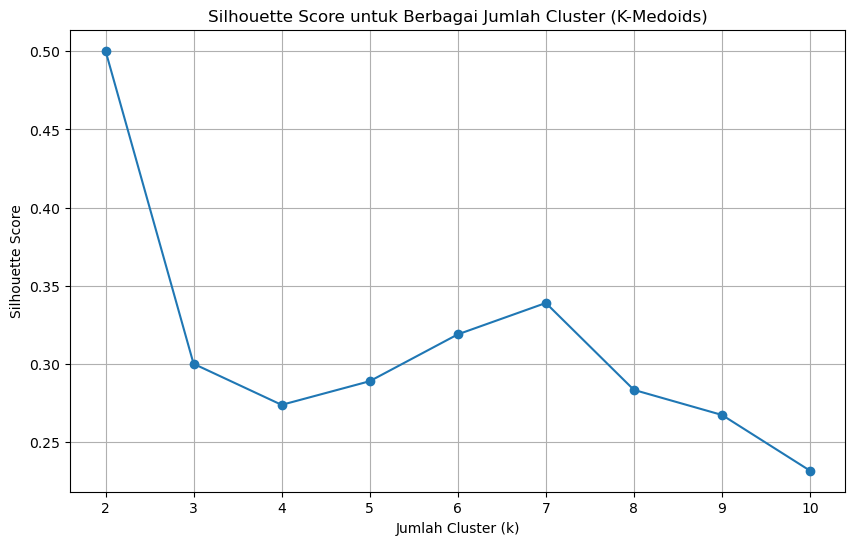

In [14]:
# Menentukan Jumlah Cluster

silhouette_scores = []
range_n_clusters = range(2, 11)

for k in range_n_clusters:
    kmedoids = KMedoids(n_clusters=k, random_state=42, method='pam')
    kmedoids.fit(df_zscore)
    labels = kmedoids.labels_
    score = silhouette_score(df_zscore, labels)
    silhouette_scores.append(score)
    print(f"Jumlah Cluster = {k}, Silhouette Score = {score:.4f}")

optimal_k = range_n_clusters[silhouette_scores.index(max(silhouette_scores))]
print(f"\nJumlah cluster optimal berdasarkan Silhouette Score: {optimal_k}")

# Plot grafik
plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, silhouette_scores, marker='o', linestyle='-')
plt.title('Silhouette Score untuk Berbagai Jumlah Cluster (K-Medoids)')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

In [15]:
# Fit Ulang
kmedoids_final = KMedoids(n_clusters= 4, random_state=42, method='pam')
kmedoids_final.fit(df_zscore)

KMedoids(method='pam', n_clusters=4, random_state=42)

In [16]:
# Cek pusat medoid
medoid_indices = kmedoids_final.medoid_indices_
medoids_data = df_zscore.iloc[medoid_indices]
print("\nPusat Medoid dari setiap cluster:")
print(medoids_data)


Pusat Medoid dari setiap cluster:
    UHH(Z-score)  RLS(Z-score)  Presentase Miskin(Z-score)
14     -0.145424     -0.594676                   -0.059423
3       0.023196      0.161721                   -0.701964
8      -0.579018     -0.869730                    1.148708
20      1.468510      1.481979                   -1.594596


In [17]:
kmedoids.n_iter_

9

In [18]:
# labeling
labels_final = kmedoids_final.labels_
df_final = df.copy()
df['Cluster'] = labels_final
print("\nData dengan label cluster:")
print(df)


Data dengan label cluster:
                           UHH    RLS  Presentase Miskin  Cluster
Kabupaten/Kota                                                   
Kabupaten Bogor          74.90   8.39               7.05        0
Kabupaten Sukabumi       74.85   7.34               6.87        0
Kabupaten Cianjur        75.80   7.33              10.14        0
Kabupaten Bandung        75.23   9.15               6.19        1
Kabupaten Garut          74.87   7.85               9.68        2
Kabupaten Tasikmalaya    74.06   7.97              10.23        2
Kabupaten Ciamis         75.26   8.10               7.39        0
Kabupaten Kuningan       75.22   7.90              11.88        2
Kabupaten Cirebon        74.98   7.65              11.00        2
Kabupaten Majalengka     74.98   7.53              10.82        2
Kabupaten Sumedang       75.29   8.74               9.10        0
Kabupaten Indramayu      74.82   6.95              11.93        2
Kabupaten Subang         75.08   7.46           

In [23]:
df['Cluster'] = df['Cluster'] + 1
for k in sorted(df['Cluster'].unique()):
    anggota = df[df['Cluster'] == k].index.tolist()
    print(f"\nCluster {k} ({len(anggota)} anggota):")
    print(", ".join(anggota))


Cluster 1 (8 anggota):
Kabupaten Bogor, Kabupaten Sukabumi, Kabupaten Cianjur, Kabupaten Ciamis, Kabupaten Sumedang, Kabupaten Purwakarta, Kabupaten Karawang, Kabupaten Pangandaran

Cluster 2 (5 anggota):
Kabupaten Bandung, Kabupaten Bekasi, Kota Sukabumi, Kota Cirebon, Kota Banjar

Cluster 3 (9 anggota):
Kabupaten Garut, Kabupaten Tasikmalaya, Kabupaten Kuningan, Kabupaten Cirebon, Kabupaten Majalengka, Kabupaten Indramayu, Kabupaten Subang, Kabupaten Bandung Barat, Kota Tasikmalaya

Cluster 4 (5 anggota):
Kota Bogor, Kota Bandung, Kota Bekasi, Kota Depok, Kota Cimahi


C:\Users\Keysha Jauzi\Documents\phyton\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


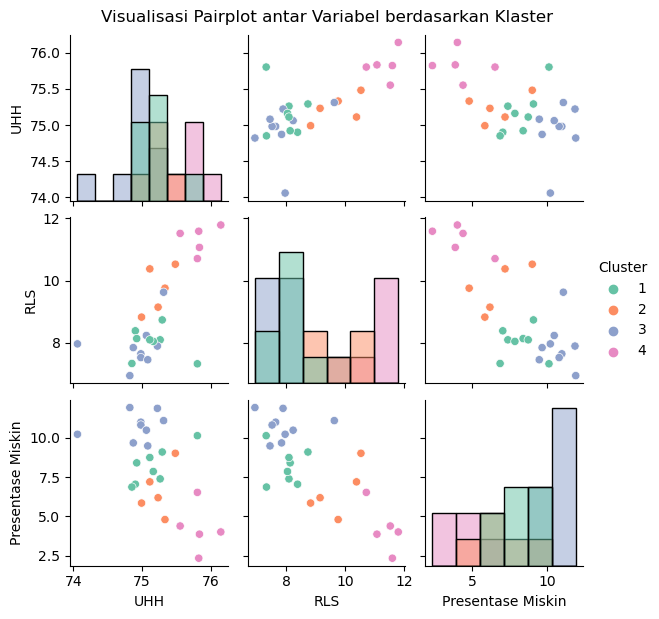

In [43]:
kolom_plot = ['UHH', 'RLS', 'Presentase Miskin', 'Cluster'] 
sns.pairplot(
    df_final[kolom_plot],
    hue='Cluster',
    diag_kind='hist',
    palette='Set2',
    height=2.0,     
    aspect=1.0
)
plt.suptitle(
    'Visualisasi Pairplot antar Variabel berdasarkan Klaster',
    y=1.02
)
plt.show()

In [21]:
# Hasil Cluster
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
print("\nRata-rata tiap variabel per klaster:")
print(cluster_summary)


Rata-rata tiap variabel per klaster:
               UHH        RLS  Presentase Miskin
Cluster                                         
0        75.161250   8.023750           8.196250
1        75.228000   9.730000           6.612000
2        74.931111   7.908889          10.735556
3        75.828000  11.336000           4.228000
